this is where we are going to pull rainfall for 2026 monsoon, without api keys


In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta
from pathlib import Path
import osmnx as ox

(6816, 4)
Total rain (mm): 1101.7

Top 10 heaviest hours:
                    time  precipitation
5726 2026-08-27 14:00:00           13.0
6428 2026-09-25 20:00:00           13.0
6426 2026-09-25 18:00:00           11.3
6429 2026-09-25 21:00:00           11.1
4580 2026-07-10 20:00:00           10.3
5207 2026-08-05 23:00:00            9.2
6427 2026-09-25 19:00:00            8.9
2962 2026-05-04 10:00:00            8.3
5738 2026-08-28 02:00:00            8.2
4509 2026-07-07 21:00:00            8.1
            total_mm  peak_hour_mm
time                              
2026-09-25      93.8          13.0
2026-09-26      41.1           5.1
2026-09-02      32.0           6.0
2026-08-06      30.0           3.2
2026-08-05      29.1           9.2
2026-08-25      28.5           3.7
2026-07-07      28.1           8.1
2026-08-28      27.9           8.2
2026-08-26      25.7           4.9
2026-07-08      25.5           6.6
2026-07-10      24.9          10.3
2026-06-13      23.4           6.9
2026-04-08  

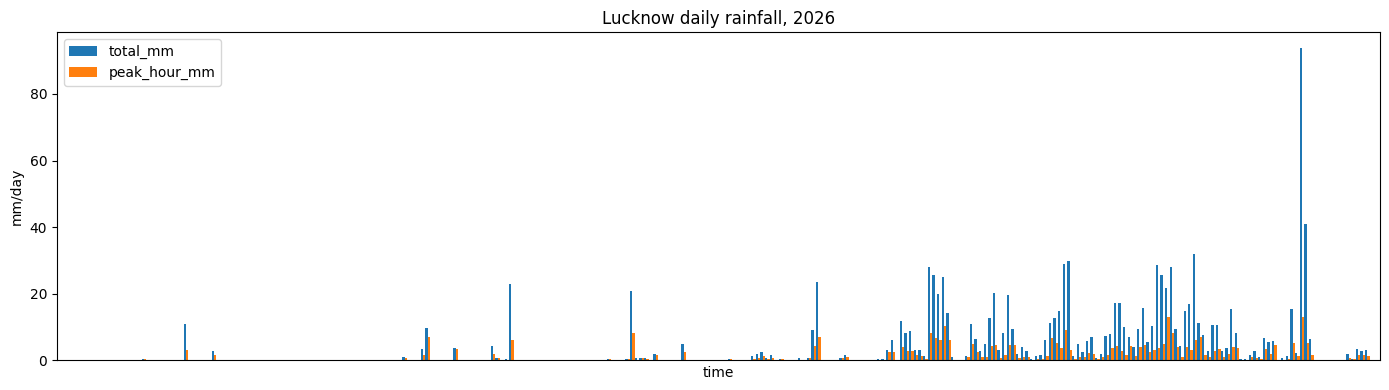

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

LAT, LON = 26.8467, 80.9462
end = date.today() - timedelta(days=5)  # archive data lags ~5 days

r = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={
        "latitude": LAT, "longitude": LON,
        "start_date": "2026-01-01", "end_date": end.isoformat(),
        "hourly": "precipitation,temperature_2m,relative_humidity_2m",
        "timezone": "Asia/Kolkata",
    },
    timeout=60,
)
r.raise_for_status()

rain = pd.DataFrame(r.json()["hourly"])
rain["time"] = pd.to_datetime(rain["time"])
rain.to_csv(RAW / "rainfall_data.csv", index=False)

print(rain.shape)
print("Total rain (mm):", round(rain["precipitation"].sum(), 1))
print("\nTop 10 heaviest hours:")
print(rain.nlargest(10, "precipitation")[["time", "precipitation"]])
daily = rain.set_index("time")["precipitation"].resample("D").agg(["sum", "max"])
daily.columns = ["total_mm", "peak_hour_mm"]
print(daily.sort_values("total_mm", ascending=False).head(15).round(1))

# Daily totals plot
daily = rain.set_index("time")["precipitation"].resample("D").agg(["sum", "max"])
daily.columns = ["total_mm", "peak_hour_mm"]
daily.plot(kind="bar", figsize=(14, 4), width=1.0)
plt.ylabel("mm/day"); plt.title("Lucknow daily rainfall, 2026")
plt.xticks([])
plt.tight_layout()
plt.savefig(RAW / "rain_2026.png")
plt.show()

             total_mm  peak_hour_mm
time                               
25 Sep 2026      93.8          13.0
26 Sep 2026      41.1           5.1
02 Sep 2026      32.0           6.0
06 Aug 2026      30.0           3.2
05 Aug 2026      29.1           9.2
25 Aug 2026      28.5           3.7
07 Jul 2026      28.1           8.1
28 Aug 2026      27.9           8.2
26 Aug 2026      25.7           4.9
08 Jul 2026      25.5           6.6
10 Jul 2026      24.9          10.3
13 Jun 2026      23.4           6.9
08 Apr 2026      22.9           6.0
27 Aug 2026      21.8          13.0
04 May 2026      20.8           8.3


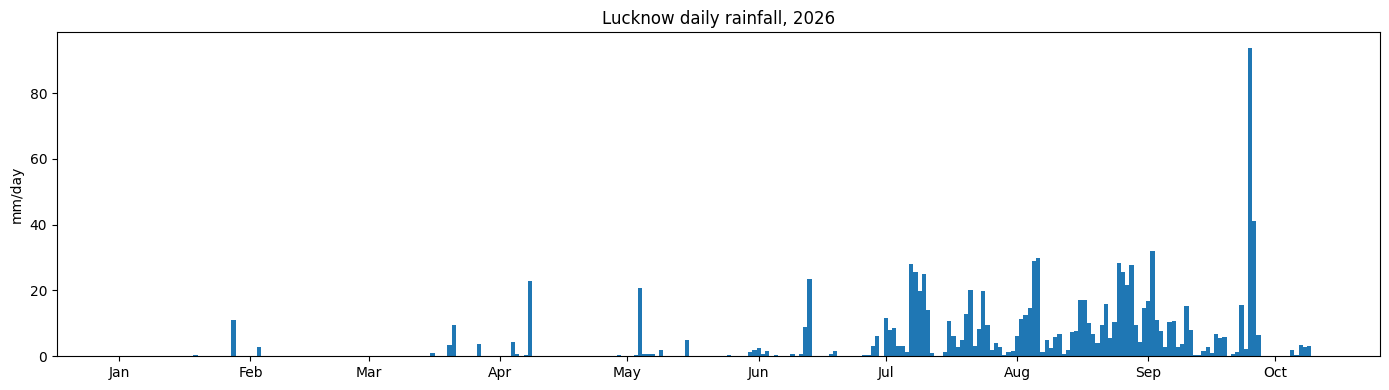

In [3]:
top = daily.sort_values("total_mm", ascending=False).head(15).round(1)
top.index = top.index.strftime("%d %b %Y")
print(top)

# Optional: a version of the plot with actual dates on the x-axis
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(daily.index, daily["total_mm"], width=1.0)
ax.set_ylabel("mm/day"); ax.set_title("Lucknow daily rainfall, 2026")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()



In [4]:
top = daily.sort_values("total_mm", ascending=False).head(15).round(1)
top.index = top.index.strftime("%d %b %Y")
print(top)

             total_mm  peak_hour_mm
time                               
25 Sep 2026      93.8          13.0
26 Sep 2026      41.1           5.1
02 Sep 2026      32.0           6.0
06 Aug 2026      30.0           3.2
05 Aug 2026      29.1           9.2
25 Aug 2026      28.5           3.7
07 Jul 2026      28.1           8.1
28 Aug 2026      27.9           8.2
26 Aug 2026      25.7           4.9
08 Jul 2026      25.5           6.6
10 Jul 2026      24.9          10.3
13 Jun 2026      23.4           6.9
08 Apr 2026      22.9           6.0
27 Aug 2026      21.8          13.0
04 May 2026      20.8           8.3


In [5]:
places = ["Hazratganj", "Gomti Nagar", "Aliganj", "Charbagh", "Chowk", "Indira Nagar", "Alambagh"]
for p in places:
    try:
        lat, lon = ox.geocode(f"{p}, Lucknow, India")
        print(f"{p},{lat:.4f},{lon:.4f}")
    except Exception as e:
        print(p, "-> not found", e)

Hazratganj,26.8548,80.9448
Gomti Nagar,26.8612,81.0039
Aliganj,26.9051,80.9480
Charbagh,26.8335,80.9264
Chowk,26.8677,80.9042
Indira Nagar,26.8823,80.9900
Alambagh,26.8140,80.9025


In [6]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LABELS = ROOT / "data" / "labels"
LABELS.mkdir(parents=True, exist_ok=True)

url = "https://www.newsdrum.in/national/late-september-deluge-batters-north-india-up-schools-shut-uttarakhand-on-red-alert-12577325"
places = {
    "Hazratganj":   (26.8548, 80.9448),
    "Gomti Nagar":  (26.8612, 81.0039),
    "Aliganj":      (26.9051, 80.9480),
    "Charbagh":     (26.8335, 80.9264),
    "Chowk":        (26.8677, 80.9042),
    "Indira Nagar": (26.8823, 80.9900),
    "Alambagh":     (26.8140, 80.9025),
}

rows = [
    {"date": "2026-09-25", "location_name": name, "lat": lat, "lon": lon,
     "severity": "high", "source": "NewsDrum", "source_url": url}
    for name, (lat, lon) in places.items()
]

df = pd.DataFrame(rows)
df.to_csv(LABELS / "waterlogging_reports.csv", index=False)
print(df)

         date location_name      lat      lon severity    source  \
0  2026-09-25    Hazratganj  26.8548  80.9448     high  NewsDrum   
1  2026-09-25   Gomti Nagar  26.8612  81.0039     high  NewsDrum   
2  2026-09-25       Aliganj  26.9051  80.9480     high  NewsDrum   
3  2026-09-25      Charbagh  26.8335  80.9264     high  NewsDrum   
4  2026-09-25         Chowk  26.8677  80.9042     high  NewsDrum   
5  2026-09-25  Indira Nagar  26.8823  80.9900     high  NewsDrum   
6  2026-09-25      Alambagh  26.8140  80.9025     high  NewsDrum   

                                          source_url  
0  https://www.newsdrum.in/national/late-septembe...  
1  https://www.newsdrum.in/national/late-septembe...  
2  https://www.newsdrum.in/national/late-septembe...  
3  https://www.newsdrum.in/national/late-septembe...  
4  https://www.newsdrum.in/national/late-septembe...  
5  https://www.newsdrum.in/national/late-septembe...  
6  https://www.newsdrum.in/national/late-septembe...  


In [7]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
RAW.mkdir(parents=True, exist_ok=True)

end = (date.today() - timedelta(days=5)).isoformat()
r = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={
        "latitude": 26.8467, "longitude": 80.9462,
        "start_date": "2022-01-01", "end_date": end,
        "hourly": "precipitation,temperature_2m,relative_humidity_2m",
        "timezone": "Asia/Kolkata",
    },
    timeout=120,
)
r.raise_for_status()
rain_all = pd.DataFrame(r.json()["hourly"])
rain_all["time"] = pd.to_datetime(rain_all["time"])
rain_all.to_csv(RAW / "rainfall_2022_2026.csv", index=False)
print(rain_all.shape)

daily = rain_all.set_index("time")["precipitation"].resample("D").agg(["sum", "max"])
daily.columns = ["total_mm", "peak_hour_mm"]
daily.index = daily.index.strftime("%d %b %Y")
print(daily.sort_values("total_mm", ascending=False).head(25).round(1))

(41880, 4)
             total_mm  peak_hour_mm
time                               
25 Sep 2026      93.8          13.0
15 Sep 2022      82.5          12.5
02 Jul 2024      80.0          11.0
04 Aug 2025      66.8          20.8
01 Jul 2024      58.6          16.2
12 Sep 2024      57.9          22.9
11 Sep 2024      57.7          13.5
30 Jun 2022      47.7          13.2
05 Jul 2024      44.2          11.1
26 Sep 2026      41.1           5.1
03 Aug 2025      40.8           9.4
09 Aug 2024      40.7           5.2
14 Sep 2022      40.2           8.1
01 Jul 2023      39.4          11.6
30 Jun 2025      38.7           9.3
24 Aug 2023      37.4          10.0
13 Jul 2023      36.8          17.9
23 Sep 2022      36.2          16.9
10 Sep 2023      36.0          15.5
12 Jul 2023      34.6           7.4
05 Oct 2022      33.7           5.7
10 Jul 2023      33.3           8.7
06 Jul 2024      33.2           8.4
01 Sep 2022      33.0          10.1
11 Sep 2023      32.9           6.5
